# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2026-01-13"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p3"
subproj <- "AVGUSTINOVA_04_05"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "PDE4B"    "MAGI1"    "ALCAM"    "NLGN1"    "ANK2"     "SSBP2"   
 [7] "CACNA2D1" "CNTNAP2"  "VPS13B"   "NFIB"     "BNC2"     "ADAMTSL1"
[13] "TRPM3"    "ZEB1"     "PARD3"    "MALAT1"   "PLEKHA5"  "NAV3"    
[19] "SLC35F4"  "RAD51B"   "MEG8"     "PLCB1"    "MIR99AHG" "IL1RAPL1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.15

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- assay_ch

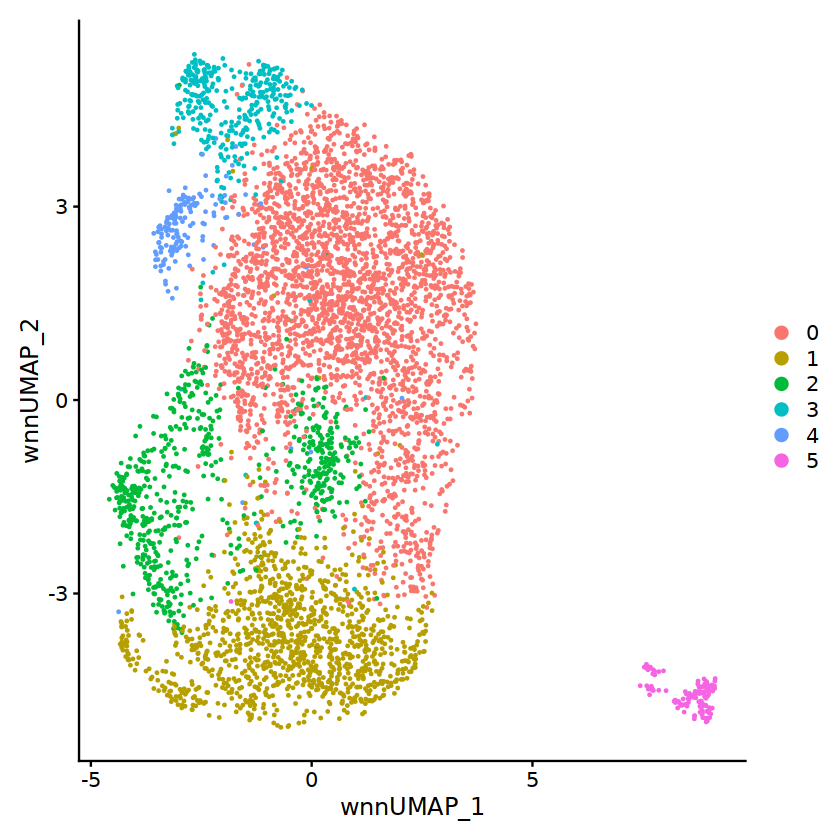

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

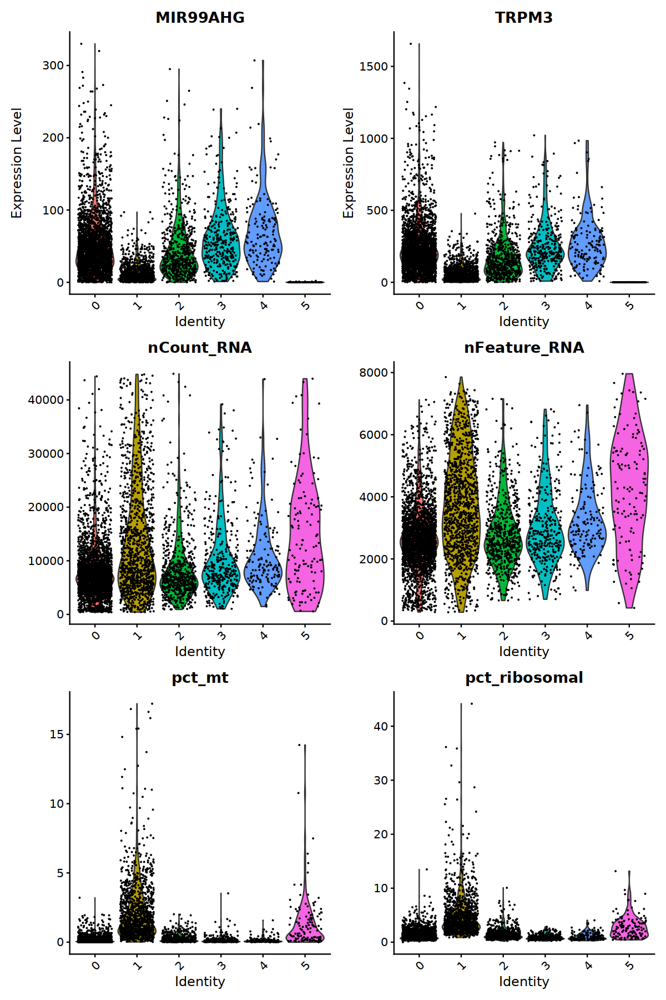

In [11]:
options(repr.plot.width = 10, repr.plot.height = 15)
VlnPlot(seurat_obj, features=c("MIR99AHG", "TRPM3",
                               'nCount_RNA','nFeature_RNA', 
                              'pct_mt','pct_ribosomal'), ncol=2,
        slot="counts")

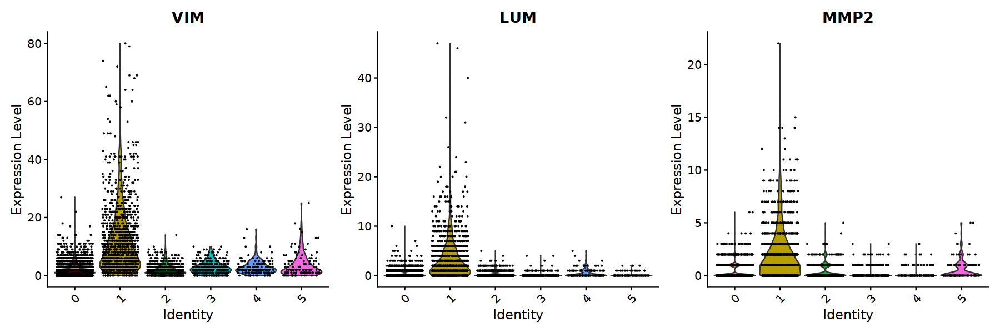

In [12]:
options(repr.plot.width = 15, repr.plot.height = 5)
VlnPlot(seurat_obj, features=c("VIM", "LUM", "MMP2"), ncol=3)

## Re-normalize

In [13]:
DefaultAssay(seurat_obj) <- assay_ch

In [14]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [15]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [16]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

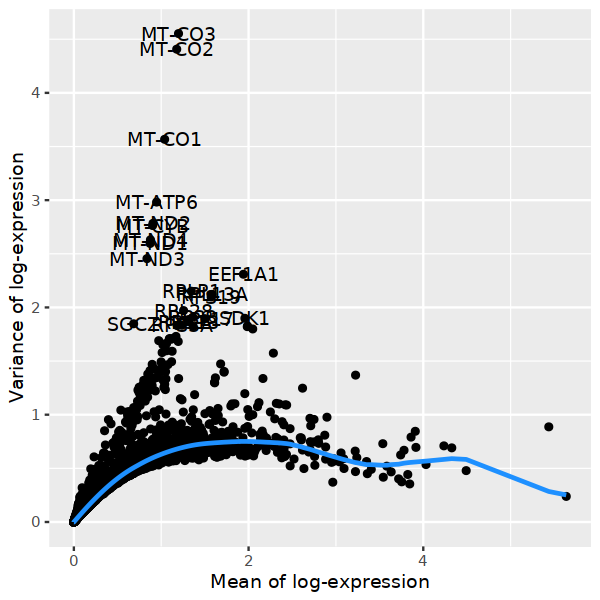

In [17]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [18]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 4135
[1] 4131


In [19]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AC011246.1, PTPRQ, AC073475.1, AC008014.1, OXR1, AL691420.1, ATP8B4, SFMBT2, NR3C2, AC073365.1 
	   CENPP, LINC00536, PTPRT, ROBO1, KCTD16, SDK1, CRPPA, SLC8A1, GRIA4, LINC00609 
	   AC044810.2, TAFA2, ADAMTS9-AS2, AC079772.1, DCC, PPM1E, PCDH7, TMTC1, AC019211.1, AL133304.3 
Negative:  MT-CO3, MT-CO2, MT-ATP6, MT-CO1, MT-ND1, MT-ND2, MT-CYB, MT-ND4, MT-ND3, RPLP1 
	   EEF1A1, RPL13A, RPS19, RPL28, RPS27A, RPL18A, RPL18, RPS8, RPS23, RPL41 
	   RPS18, RPL17, RPS15A, RPS3A, RPL10, RPLP0, RPS12, RPS28, RPL7A, TPT1 
PC_ 2 
Positive:  DOCK4, LRMDA, FRMD4B, SLC9A9, MSR1, FMN1, DOCK2, PLXDC2, ZEB2, PTPRC 
	   DPYD, IQGAP2, ITPR2, SLCO2B1, ELMO1, ATXN1, ARHGAP15, PSD3, FMNL2, MCTP1 
	   FYB1, UTRN, DOCK8, VAV3, MEF2C, F13A1, CELF2, DAPK1, GAB2, MS4A6A 
Negative:  BX284613.2, PTPRQ, AL365295.1, PPFIA2, MIR3681HG, AC044810.2, LUM, COL3A1, TTC29, RPS29 
	   LINC01572, SERPINF1, NCAM2, RPS4X, RPL21, ERP29, RPSA, DLK1, RPL30, SNHG29 
	   RPL10A,

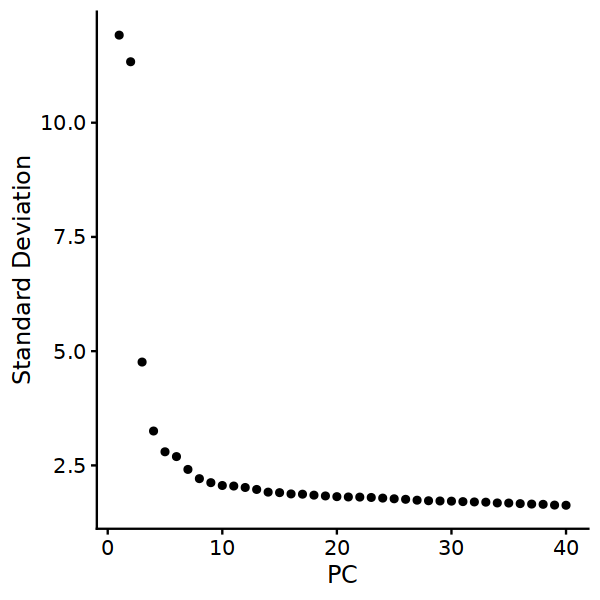

In [20]:
ElbowPlot(seurat_obj, n=40)

In [21]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


08:47:43 UMAP embedding parameters a = 0.9922 b = 1.112

08:47:43 Read 5247 rows and found 15 numeric columns

08:47:43 Using Annoy for neighbor search, n_neighbors = 30

08:47:44 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

08:47:44 Writing NN index file to temp file /scratch_tmp/52684042/RtmpG6gTjZ/file1652049b490c3

08:47:44 Searching Annoy index using 1 thread, search_k = 3000

08:47:46 Annoy recall = 100%

08:47:47 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

08:47:47 9 smooth knn distance failures

08:47:49 Initializing from normalized Laplacian + noise (using irlba)

08:47:49 Commencing optimization for 500 epochs, with 222518 positive edges

08:48:04 Optimization fi

In [22]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [23]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

08:48:19 UMAP embedding parameters a = 0.9922 b = 1.112

08:48:19 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

08:48:21 Initializing from normalized Laplacian + noise (using irlba)

08:48:21 Commencing optimization for 500 epochs, with 157628 positive edges

08:48:37 Optimization finished



In [24]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = as.numeric(reso),
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5247
Number of edges: 198987

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9351
Number of communities: 5
Elapsed time: 0 seconds


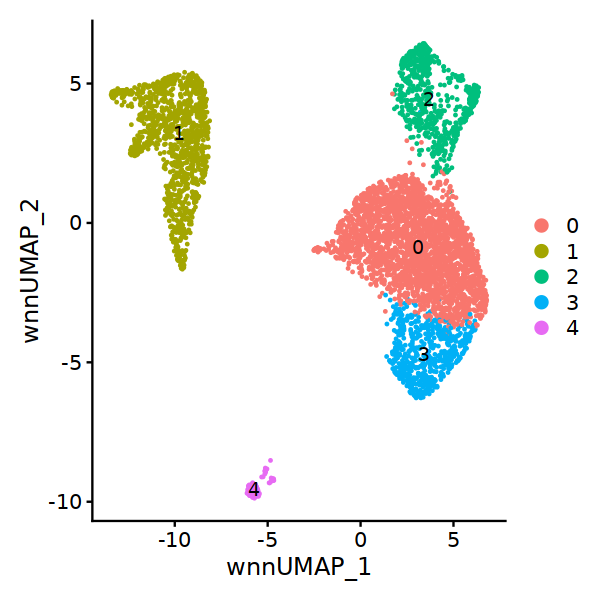

In [25]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [26]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4



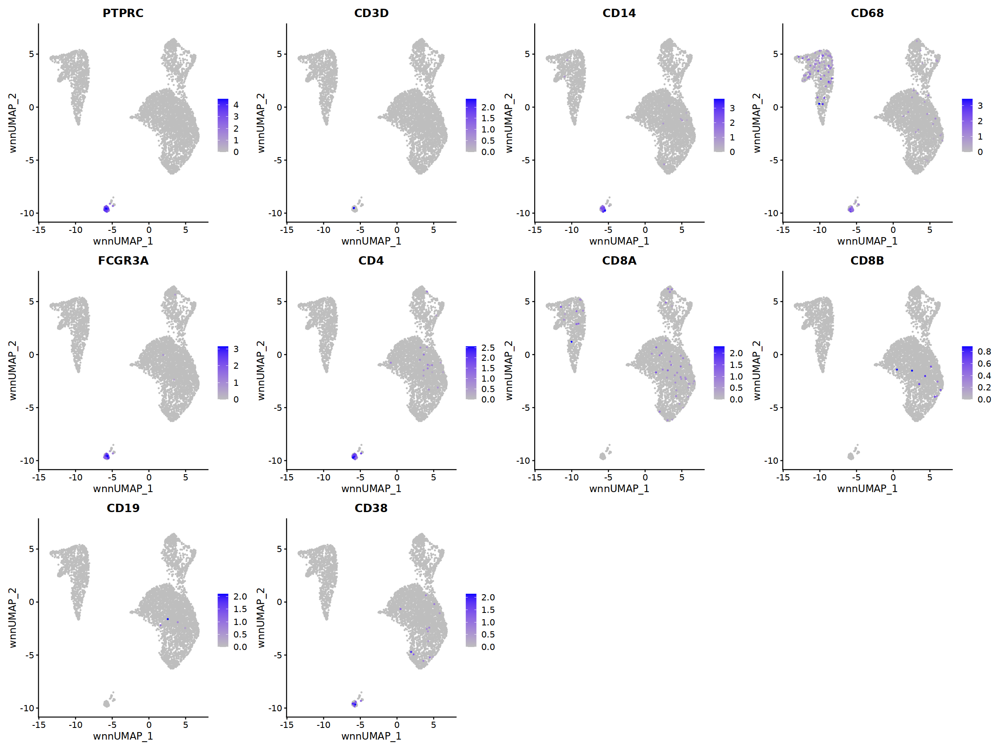

In [27]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

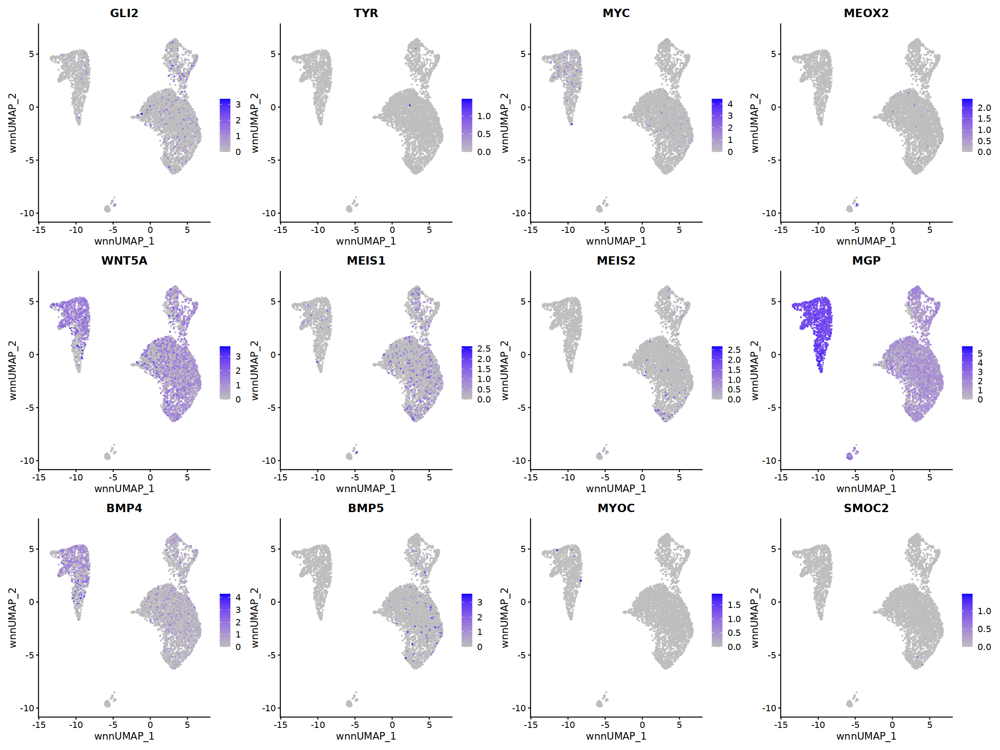

In [28]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

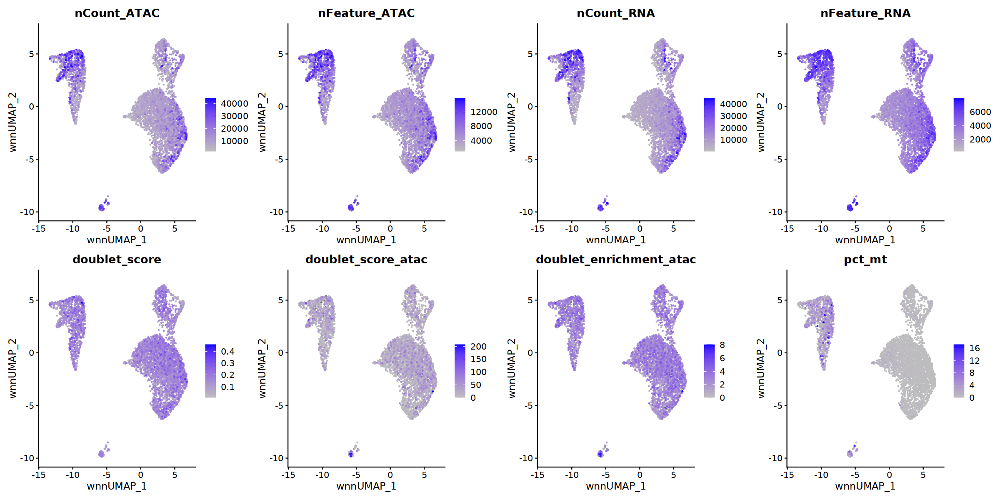

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

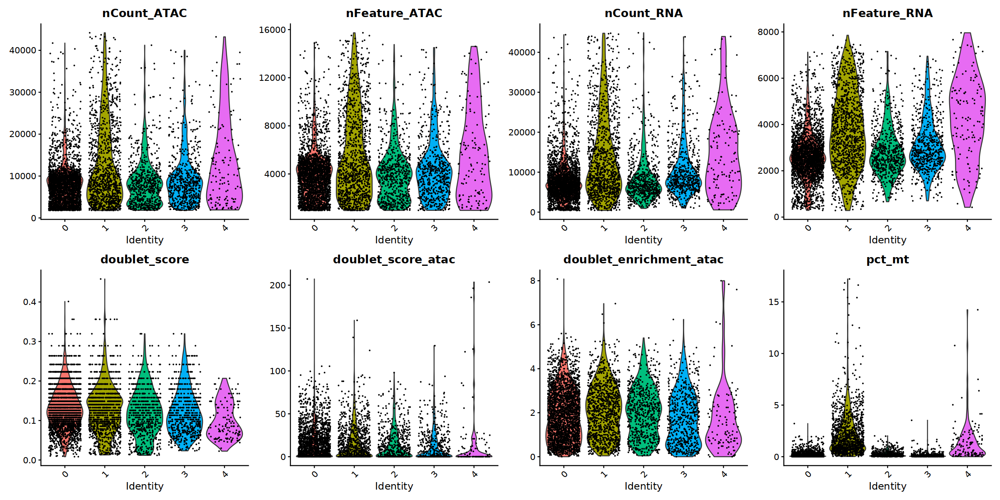

In [30]:
VlnPlot(seurat_obj,feature=qc_vars, ncol = 4)

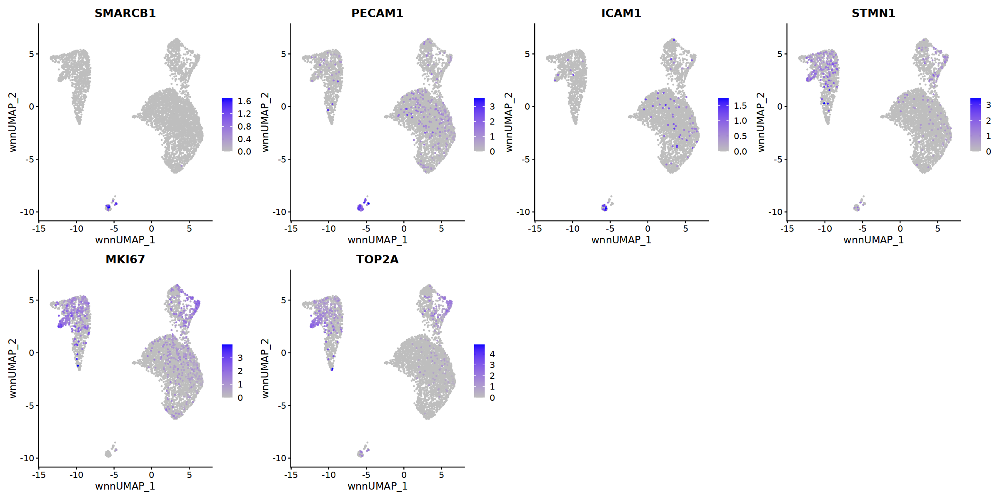

In [31]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

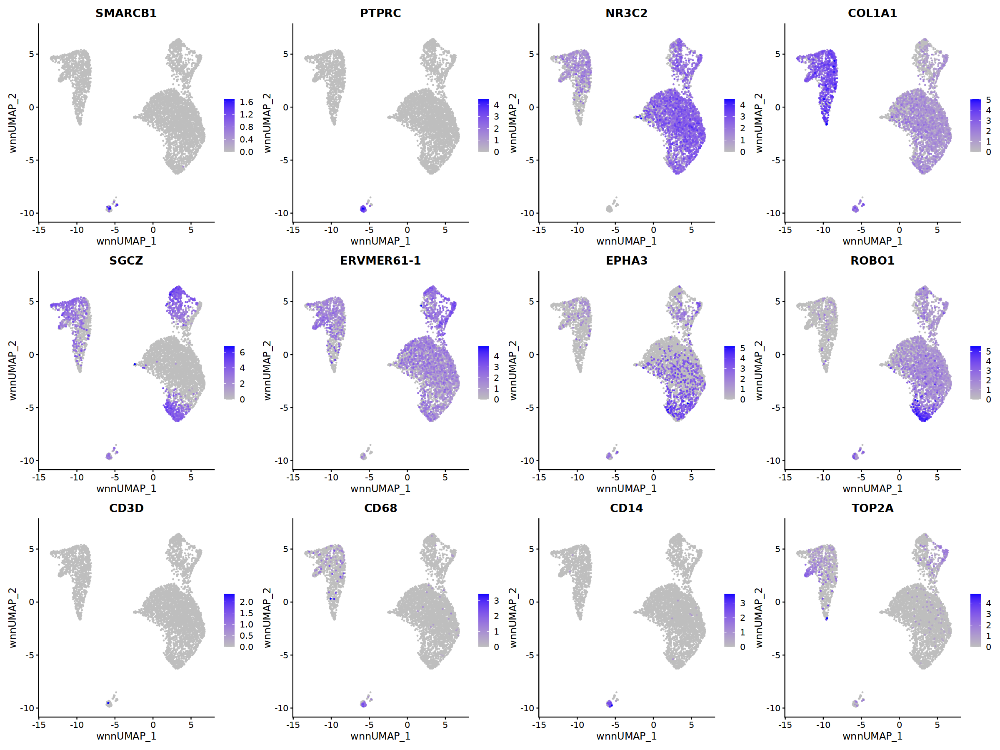

In [32]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC", "NR3C2",
                              "COL1A1","SGCZ", "ERVMER61-1", "EPHA3",
                              "ROBO1", "CD3E", "CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

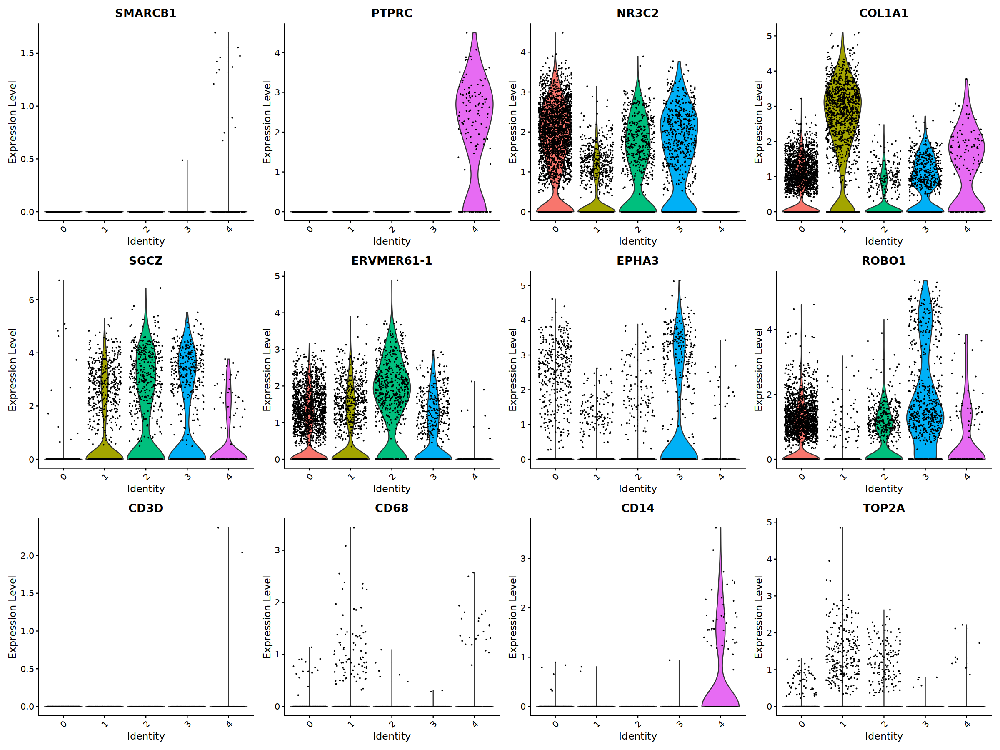

In [33]:
VlnPlot(seurat_obj,feature=vars2plot, ncol = 4)

## Filter cells

Cluster 1 low quality cells 

In [34]:
rna.markers %>% 
  dplyr::filter(cluster == "1") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
MT-CO2,0,6.105076,0.993,0.028,0,1,MT-CO2
MT-CO3,0,6.089923,0.992,0.028,0,1,MT-CO3
MT-CO1,0,5.735691,0.976,0.027,0,1,MT-CO1
MT-ND2,0,5.351915,0.962,0.024,0,1,MT-ND2
MT-CYB,0,5.208411,0.960,0.024,0,1,MT-CYB
MT-ATP6,0,5.191199,0.965,0.027,0,1,MT-ATP6
MT-ND1,0,5.141002,0.956,0.025,0,1,MT-ND1
MT-ND4,0,5.116963,0.953,0.027,0,1,MT-ND4
MT-ND3,0,5.088911,0.944,0.023,0,1,MT-ND3


Potential doublets mixing with immune cells

In [35]:
rna.markers %>% 
  dplyr::filter(cluster == "4") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
DOCK4,0.000000e+00,4.969343,0.840,0.009,0.000000e+00,4,DOCK4
LRMDA,0.000000e+00,4.880728,0.808,0.001,0.000000e+00,4,LRMDA
SLC9A9,0.000000e+00,4.451375,0.848,0.001,0.000000e+00,4,SLC9A9
PLXDC2,0.000000e+00,4.437301,0.776,0.006,0.000000e+00,4,PLXDC2
DPYD,0.000000e+00,4.434290,0.848,0.013,0.000000e+00,4,DPYD
ZEB2,0.000000e+00,4.349583,0.832,0.000,0.000000e+00,4,ZEB2
F13A1,0.000000e+00,4.337961,0.648,0.000,0.000000e+00,4,F13A1
PRKG1,3.223301e-13,4.212165,0.184,0.047,9.463288e-09,4,PRKG1
FRMD4B,0.000000e+00,4.211339,0.800,0.000,0.000000e+00,4,FRMD4B


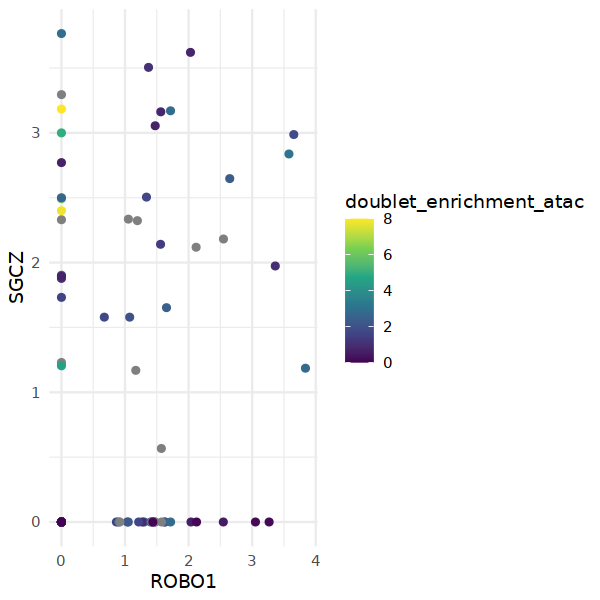

In [36]:
options(repr.plot.width = 5, repr.plot.height = 5)
data <- FetchData(seurat_obj, vars = c("seurat_clusters",
                                       "doublet_enrichment_atac", 
                                       "SGCZ", "PTPRC", "ROBO1",
                                       "PECAM1", "SMARCB1"))
data <- data[data$seurat_clusters == 4, ]
ggplot(data, aes(x = ROBO1, y = SGCZ, color = doublet_enrichment_atac)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

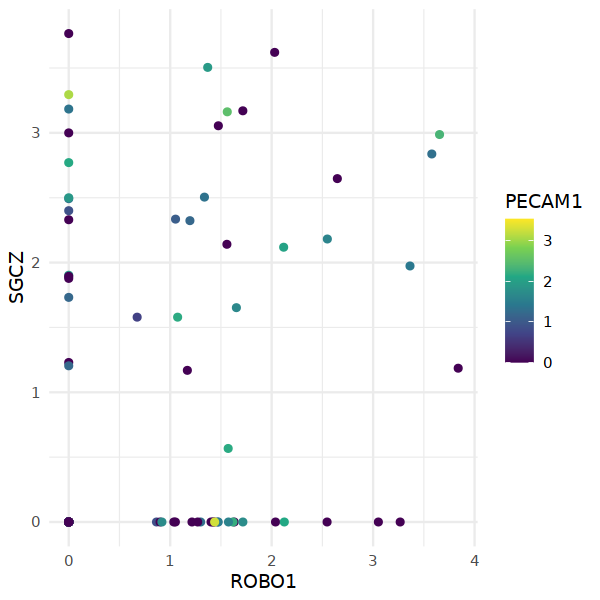

In [37]:
ggplot(data, aes(x = ROBO1, y = SGCZ, color = PECAM1)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

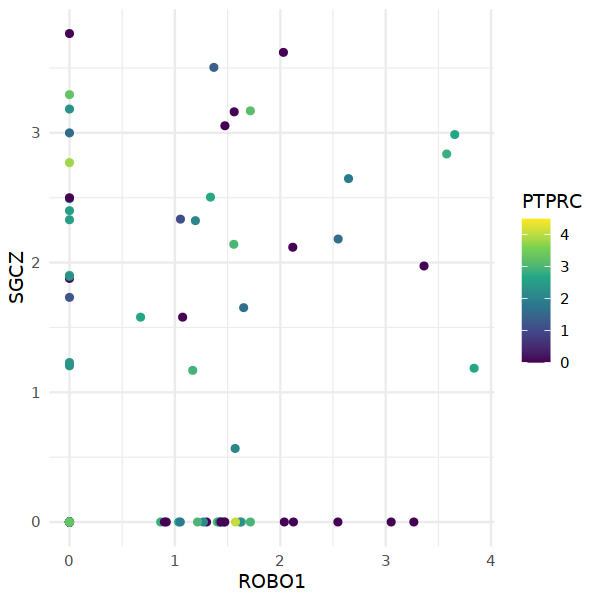

In [38]:
ggplot(data, aes(x = ROBO1, y = SGCZ, color = PTPRC)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

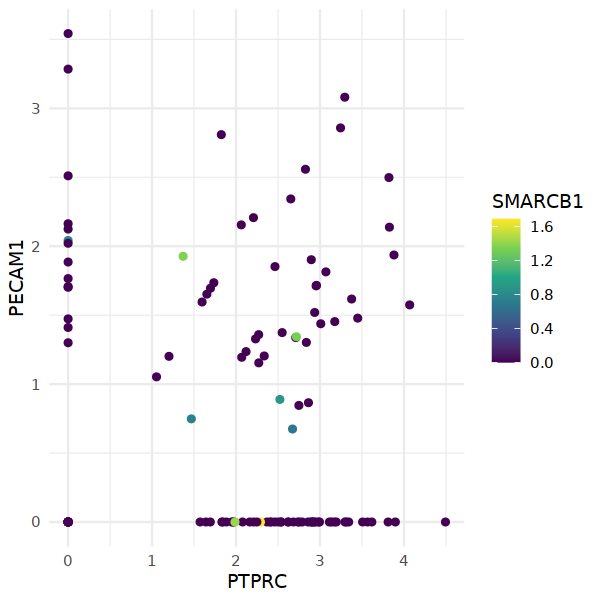

In [39]:
ggplot(data, aes(x = PTPRC, y = PECAM1, color =SMARCB1)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

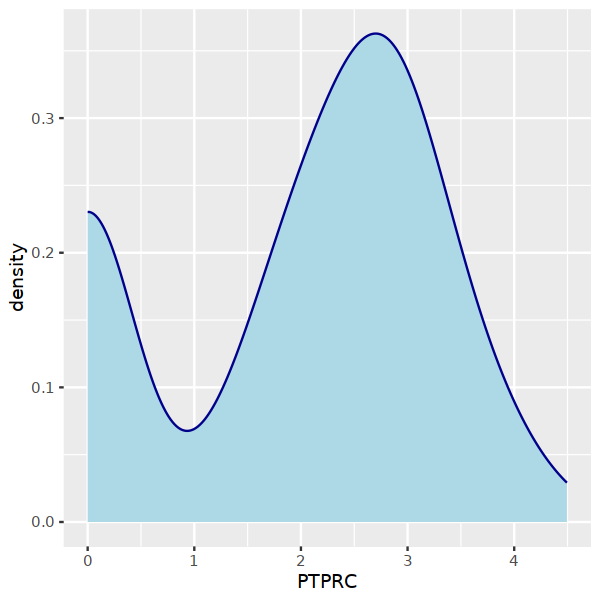

In [40]:
ggplot(data, aes(x=PTPRC))+
  geom_density(color="darkblue", fill="lightblue")

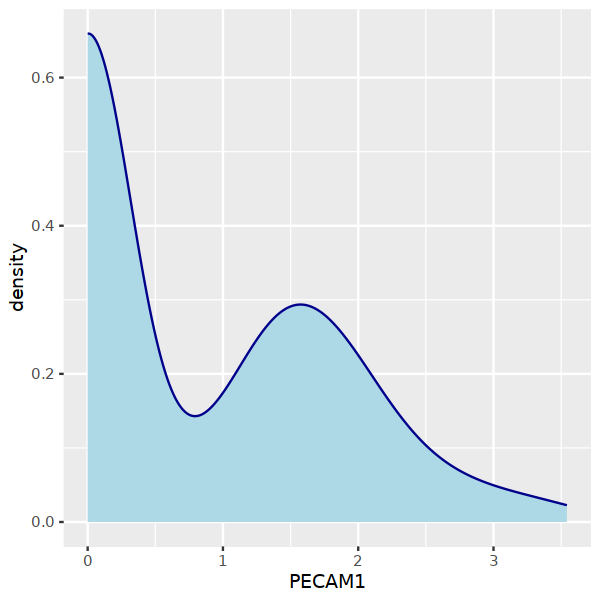

In [41]:
ggplot(data, aes(x=PECAM1))+
  geom_density(color="darkblue", fill="lightblue")

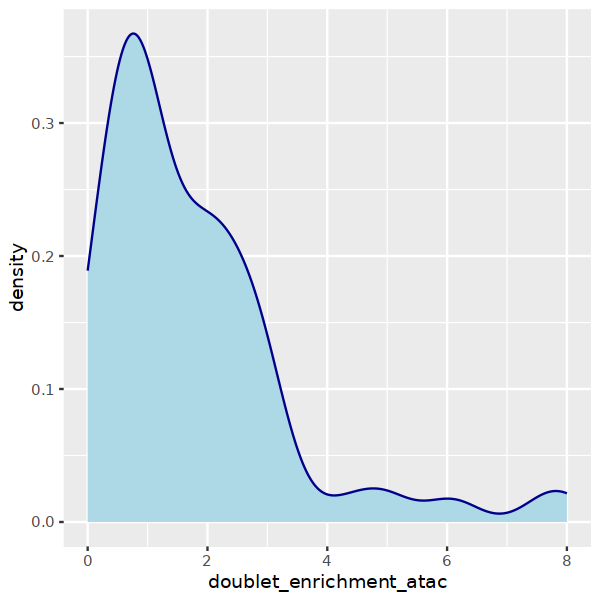

In [42]:
ggplot(data, aes(x=doublet_enrichment_atac))+
  geom_density(color="darkblue", fill="lightblue")

Get barcodes of potential doublets 

In [43]:
barcodes <- data %>%
  dplyr::filter((doublet_enrichment_atac > 4) | (ROBO1 > 0.2 & SGCZ > 0.2)) %>%
  rownames()

Remove loW quality cells and doublets from object

In [44]:
seurat_obj <- subset(seurat_obj, cells = barcodes, invert=T)

In [45]:
seurat_obj <- subset(seurat_obj, ident=1, invert=T)

## Re-process object after filtering

### RNA

In [46]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [47]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

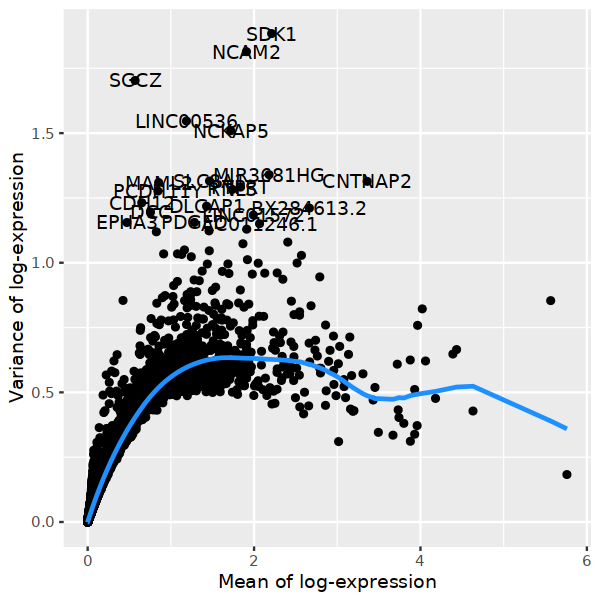

In [48]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [49]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  DOCK4, LRMDA, FRMD4B, MSR1, SLC9A9, DOCK2, FMN1, PLXDC2, PTPRC, ZEB2 
	   DPYD, SLCO2B1, IQGAP2, ITPR2, ATXN1, ELMO1, ARHGAP15, MCTP1, FYB1, PSD3 
	   UTRN, MT-CO3, F13A1, MT-CO2, DOCK8, VAV3, CELF2, MTSS1, FMNL2, MT-CO1 
Negative:  TRPM3, IL1RAPL1, CNTNAP2, AC044810.2, BX284613.2, PPFIA2, AL365295.1, GRIA4, TTC29, MIR3681HG 
	   AC019211.1, AC011246.1, LINC01572, IDO2, AC073475.1, PCDH7, PTPRT, HMGA2, NCAM2, RNLS 
	   NR3C2, CRPPA, DLGAP1, ACSM3, SDK1, AL691420.1, PDGFD, AC073365.1, AC079772.1, LINC00536 
PC_ 2 
Positive:  TRPM3, IL1RAPL1, FYB1, SLCO2B1, F13A1, CD163L1, IQGAP2, TFEC, DTNA, DOCK2 
	   PDGFC, HLA-DRB1, LDLRAD4, FPR3, HLA-DRA, PTPRC, IGSF21, MS4A7, LITAF, APBB1IP 
	   MS4A6A, CIITA, DAPK1, RGS1, SYK, TRPM2, FMN1, KCNMA1, PLXDC2, MRC1 
Negative:  MAST4, PIEZO2, LDB2, MYO1B, PTPRK, RBMS3, COL4A1, COL4A2, DLC1, LHFPL6 
	   ITGA1, LAMA4, CCDC102B, NRG3, PDGFRB, FRY, SOX5, NRXN3, RNF152, EDIL3 
	   FN1, PRKG1, GRM8, SEMA5A,

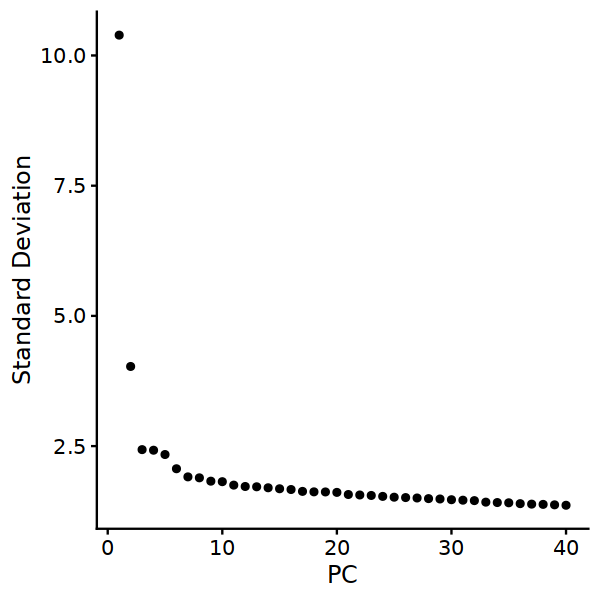

In [50]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [51]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [52]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



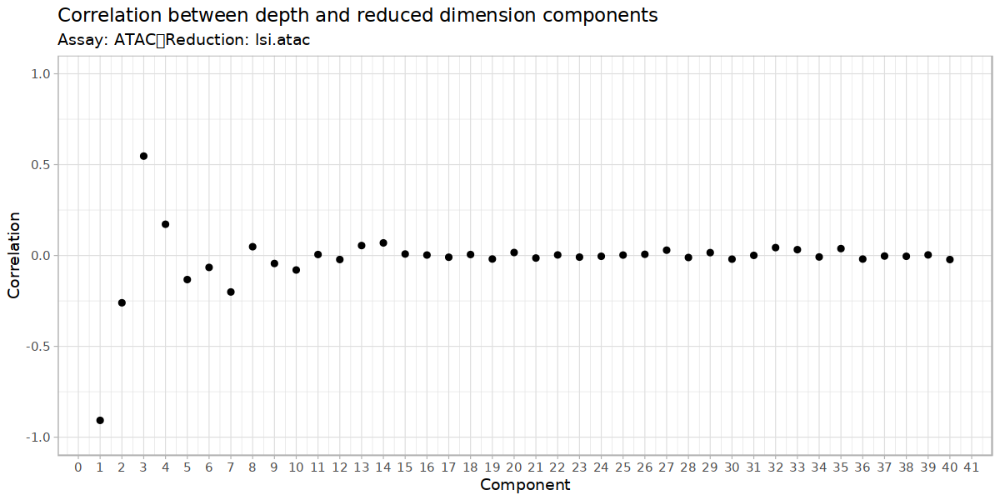

In [53]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

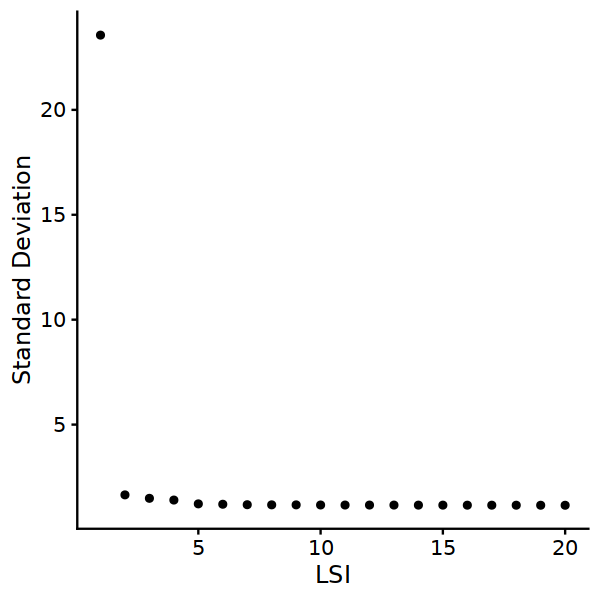

In [54]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [55]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [56]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

08:51:53 UMAP embedding parameters a = 0.9922 b = 1.112

08:51:54 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

08:51:55 Initializing from normalized Laplacian + noise (using irlba)

08:51:55 Commencing optimization for 500 epochs, with 125918 positive edges

08:52:08 Optimization finished



In [57]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 4029
Number of edges: 150750

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9367
Number of communities: 5
Elapsed time: 0 seconds


1 singletons identified. 4 final clusters.



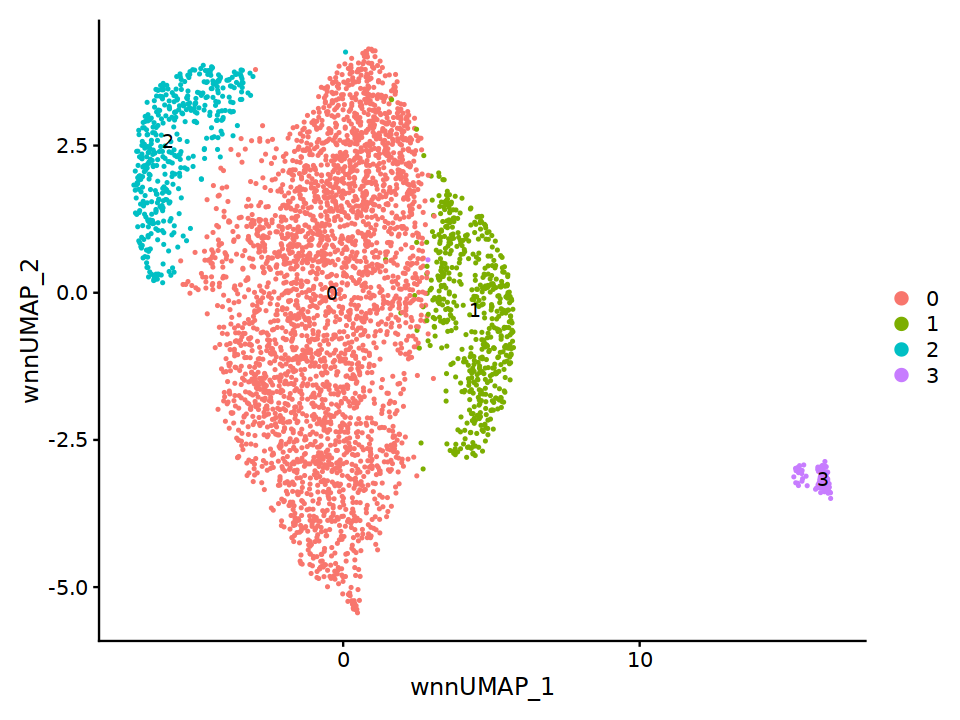

In [58]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [59]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, 
                              logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3



In [60]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

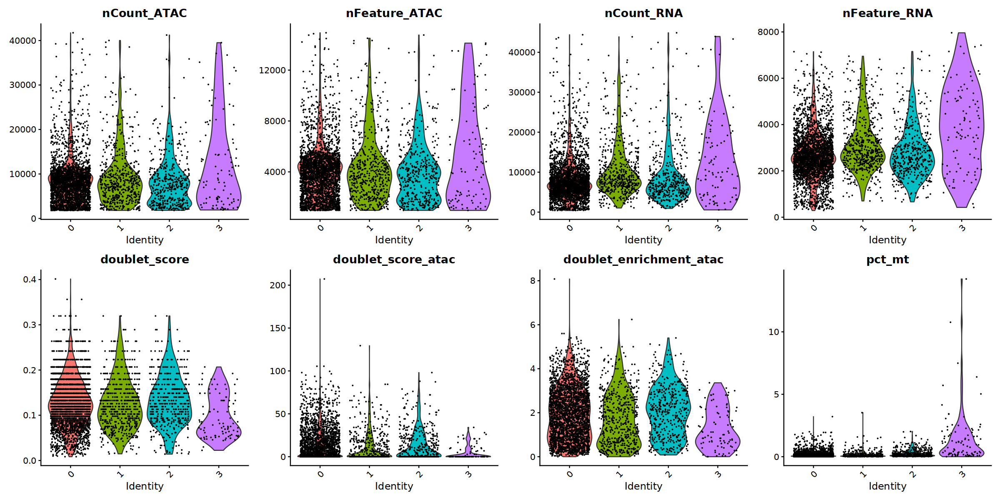

In [61]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

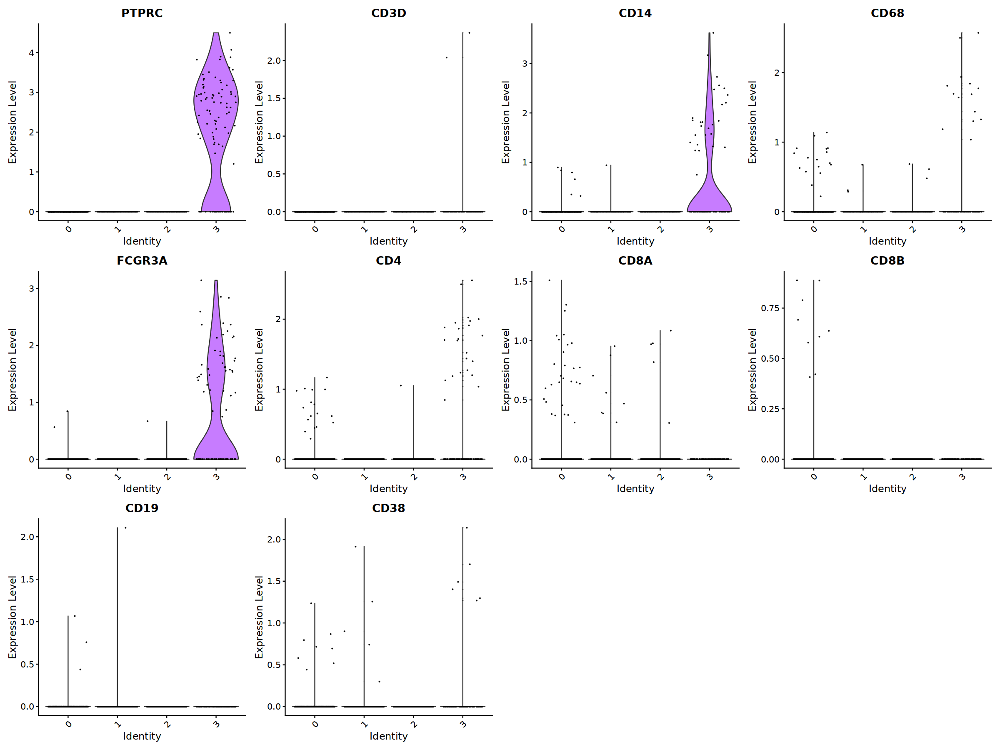

In [62]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

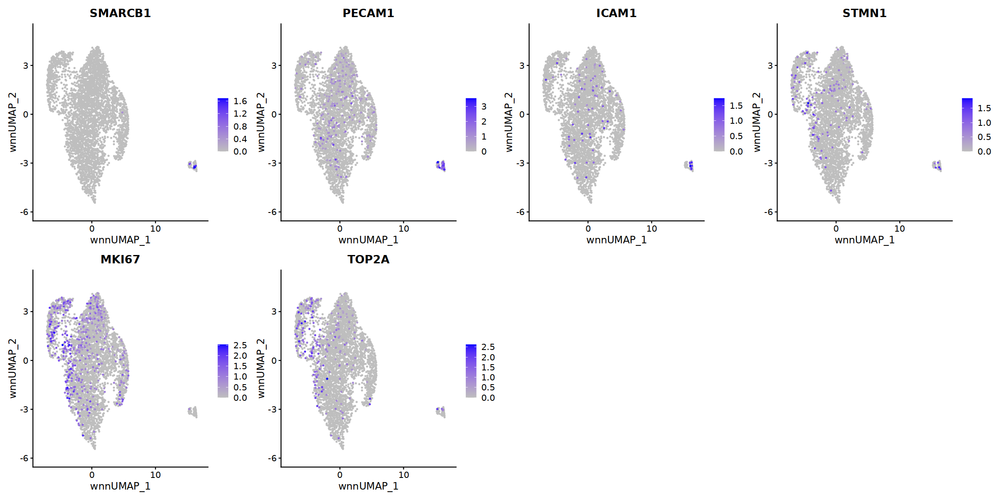

In [63]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1",
           "MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

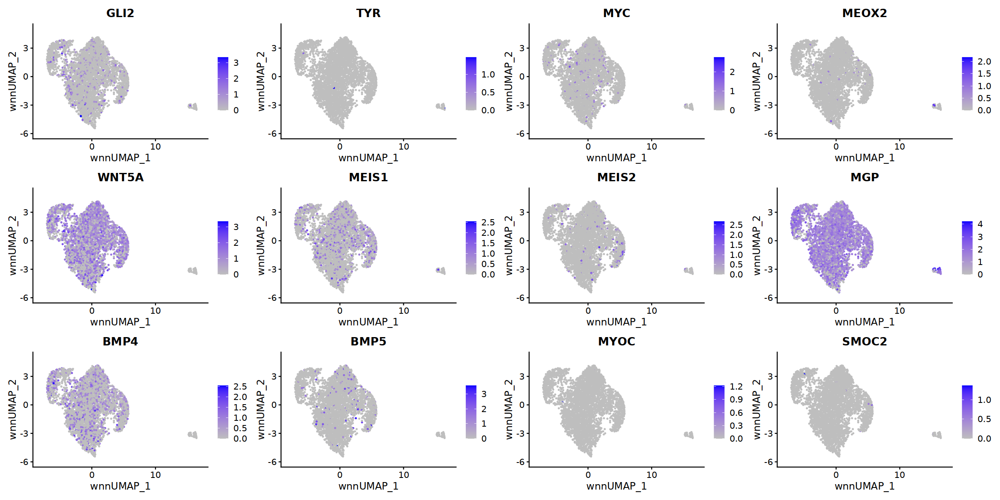

In [64]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

In [65]:
rna.markers %>% 
  dplyr::filter(cluster == "2") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
LINC01099,0.000000e+00,3.8779393,0.775,0.021,0.000000e+00,2,LINC01099
SGCZ1,2.473792e-303,2.7978798,0.828,0.099,7.262806e-299,2,SGCZ
ESR1,0.000000e+00,2.5914708,0.559,0.008,0.000000e+00,2,ESR1
ADGRL2,0.000000e+00,2.3996083,0.747,0.078,0.000000e+00,2,ADGRL2
LRRC4C,1.047360e-285,2.2420059,0.464,0.016,3.074945e-281,2,LRRC4C
PLCE11,5.765005e-137,1.9791268,0.429,0.059,1.692548e-132,2,PLCE1
CNTNAP5,0.000000e+00,1.9107654,0.534,0.004,0.000000e+00,2,CNTNAP5
TMEFF2,3.283870e-98,1.8926533,0.311,0.041,9.641115e-94,2,TMEFF2
GRIK21,2.540565e-107,1.7810544,0.422,0.074,7.458845e-103,2,GRIK2


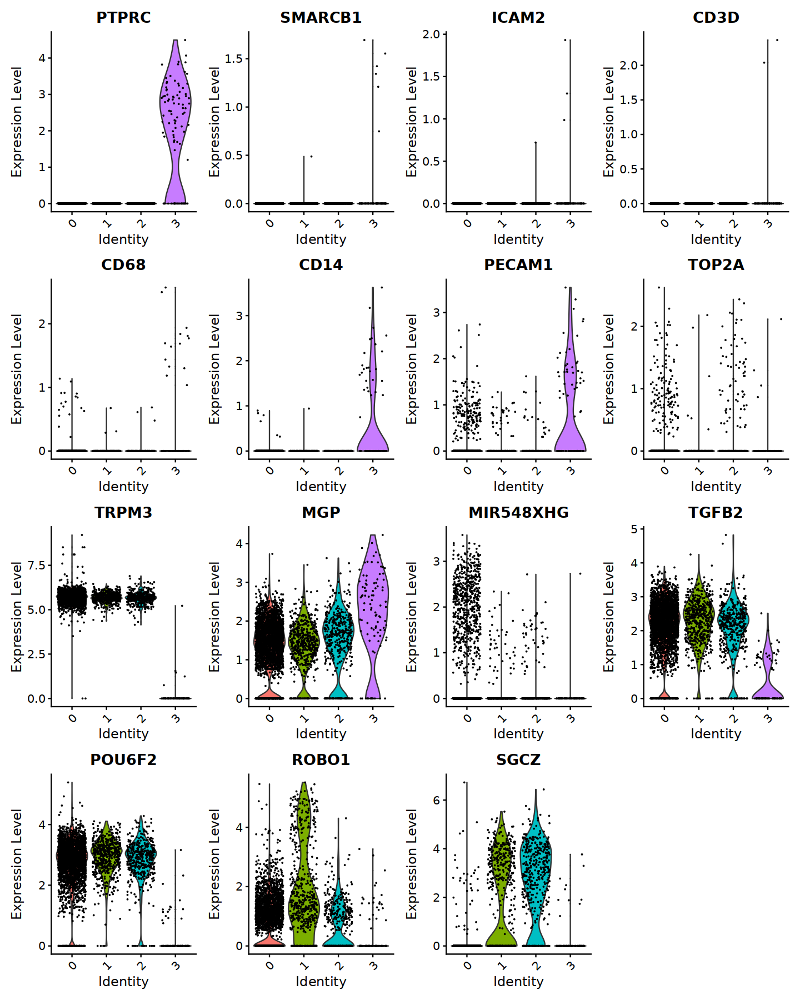

In [66]:
options(repr.plot.width = 12, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=c("PTPRC", "SMARCB1", "ICAM2", "CD3D",
                              "CD68", "CD14", "PECAM1", "TOP2A",
                              "TRPM3","MGP","MIR548XHG", 
                              "TGFB2", "POU6F2", "ROBO1", "SGCZ"), 
        ncol = 4, pt.size=0.01)

### Rename

In [67]:
rename_clusters <- c("0"="Tumor TRPM3", "1"="Tumor ROBO1",
                     "2"="Tumor SGCZ", "3"="Immune Cells")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [68]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [69]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [70]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [71]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [72]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune



In [73]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

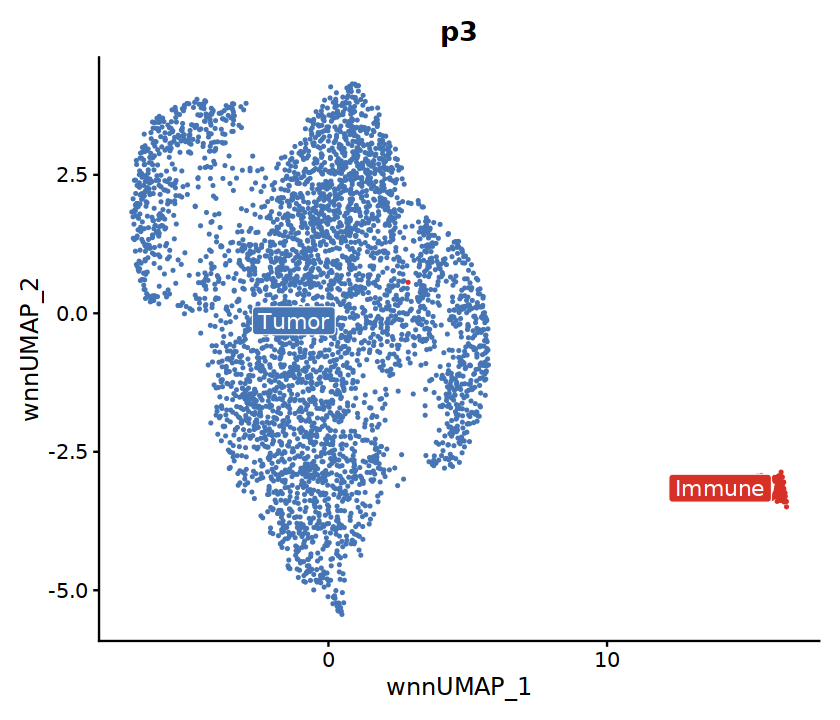

In [74]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [75]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [76]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [77]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

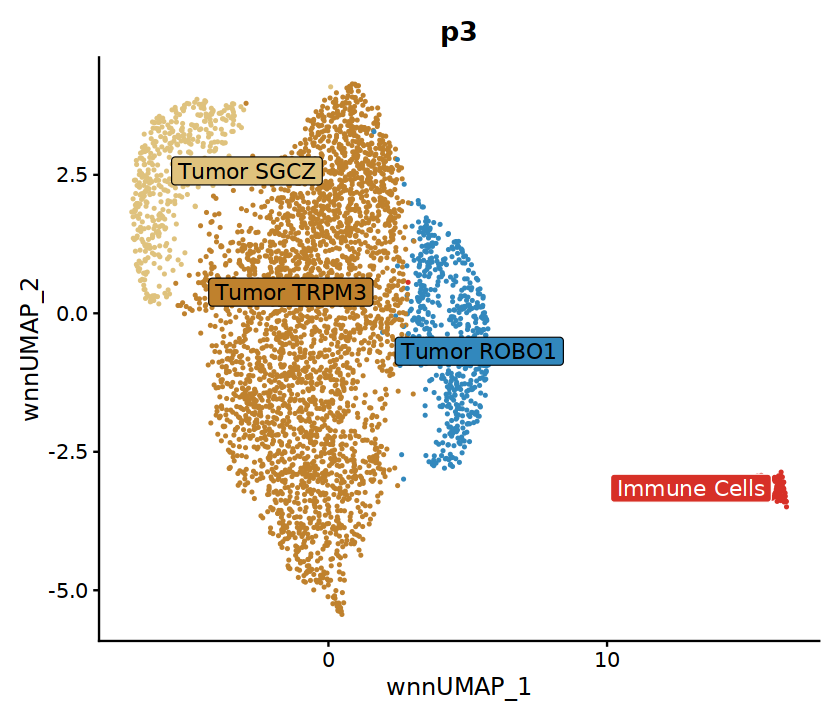

In [78]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [79]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

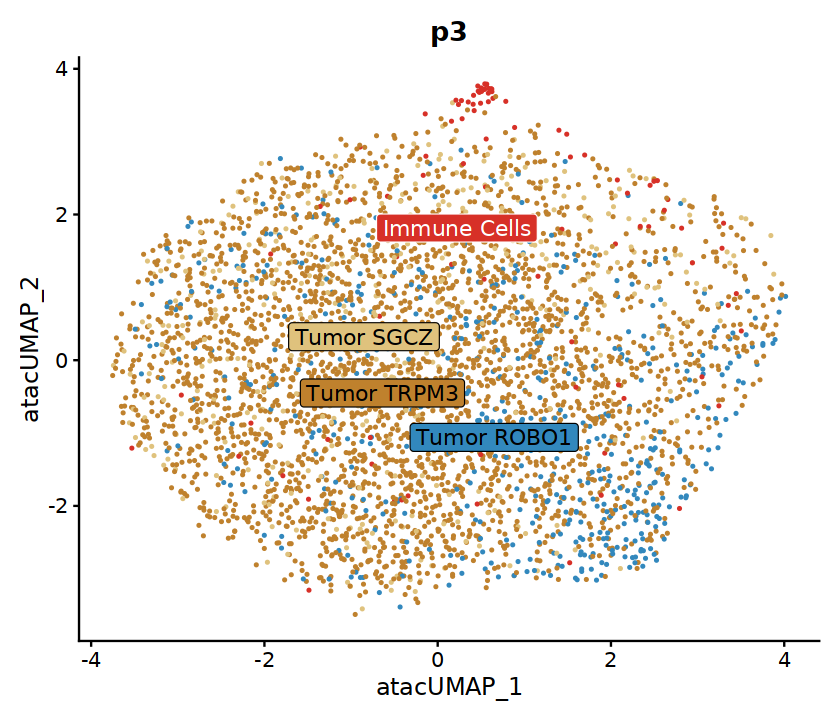

In [80]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [81]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

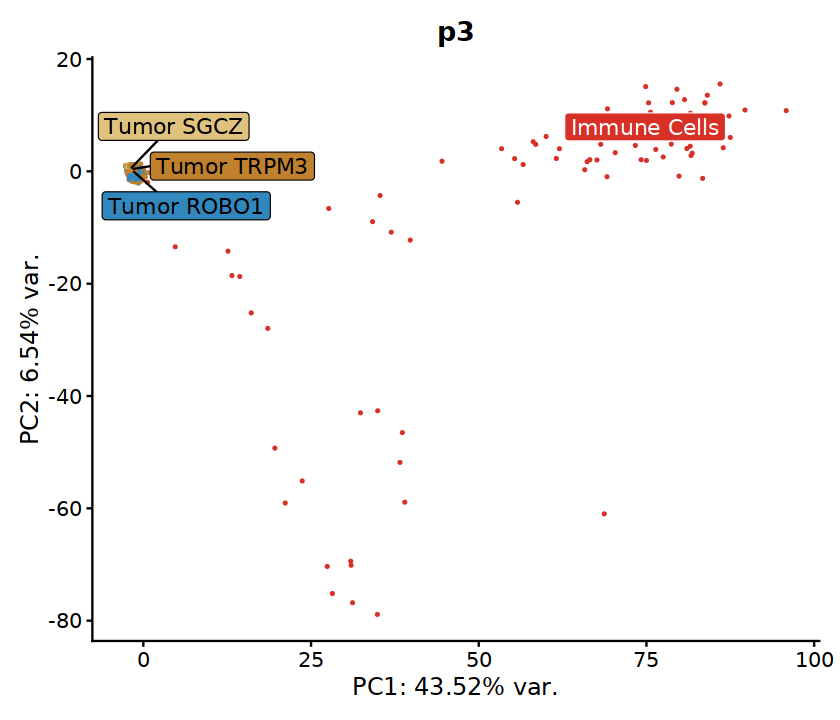

In [82]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

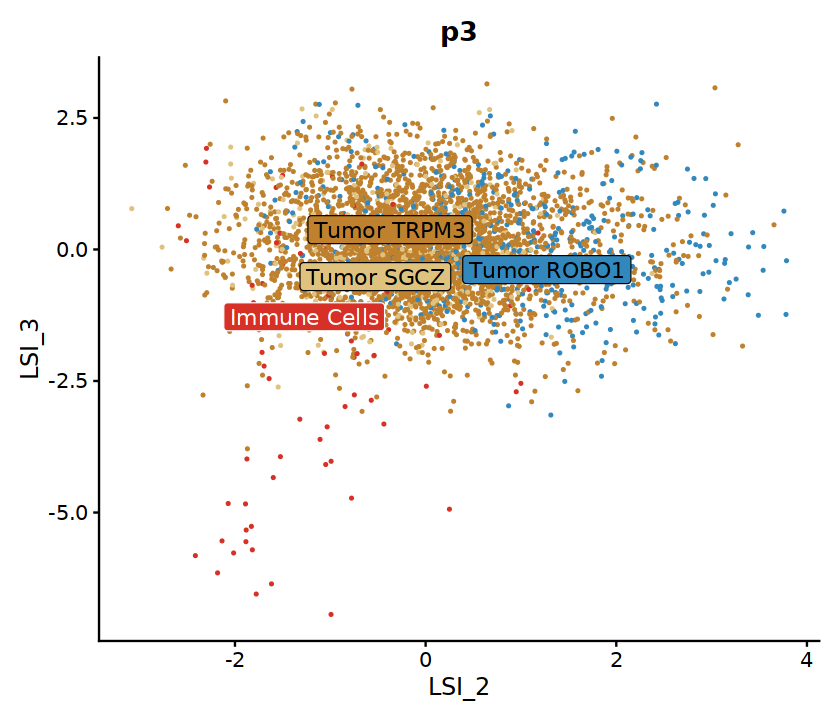

In [83]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

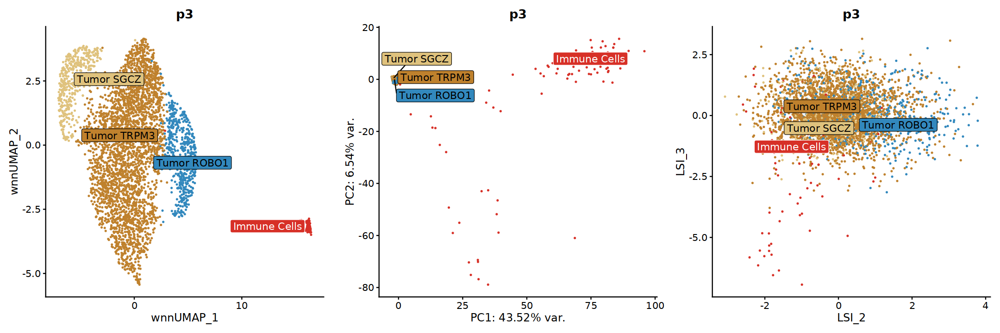

In [84]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [85]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [86]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("POU6F2"), markers) ## common markers to all clusters

In [87]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

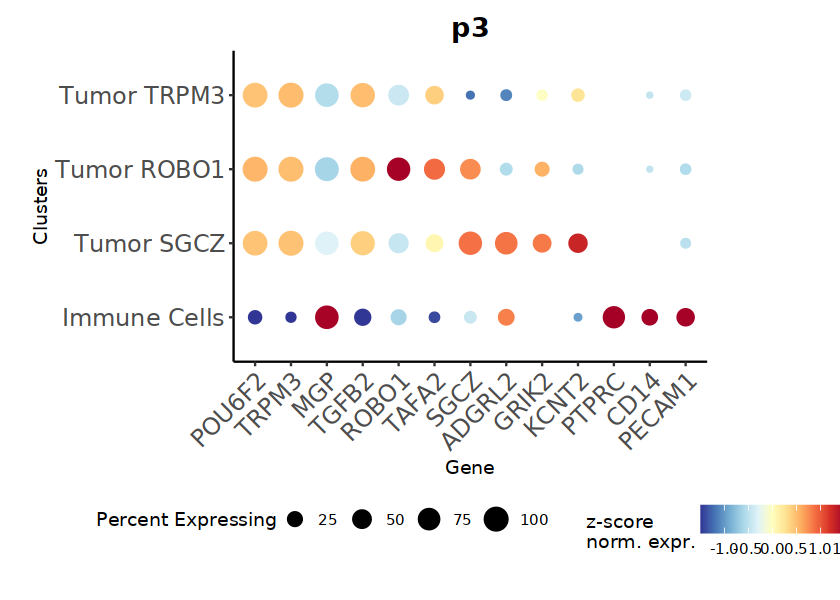

In [88]:
options(repr.plot.width = 7, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1 <- dp1 + theme(
        plot.margin = margin(t = 10, r = 80, b = 20, l = 20)
    )
dp1

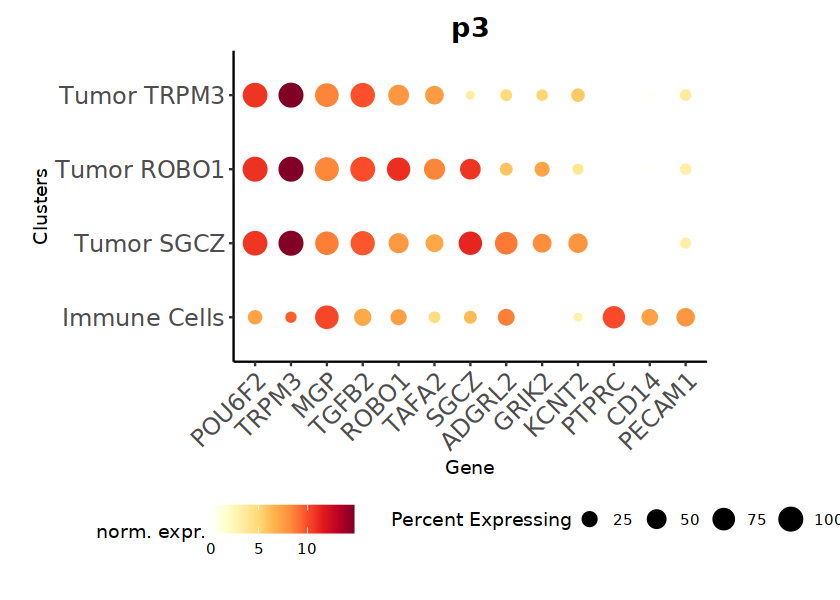

In [89]:
options(repr.plot.width = 7, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2 <- dp2 + theme(
        plot.margin = margin(t = 10, r = 80, b = 20, l = 20)
    )
dp2

In [90]:
ggsave(plot = dp1, width = 7, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [91]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [92]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [93]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [94]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    